# 보너스 실습 — 피부색으로 얼굴 찾아 고양이 얼굴로 바꾸기
## 학습 없이, 색과 마스크만으로 만드는 ‘고전적인’ 얼굴 바꾸기

딥러닝 검출기(YuNet)와 Haar 검출기는 우주인 사진에서 얼굴 상자를 바로 찾아 줍니다. 이번 실습에서는 검출기 없이 **피부색**만으로 얼굴을 찾고, 그 자리에 **고양이 얼굴**을 자연스럽게 합성합니다. 인덱싱 실습 1~4/4에서 배운 것을 그대로 씁니다.

| 단계 | 쓰는 기술 | 복습 |
|---|---|---|
| 피부색 숫자로 보기 | RGB → YCrCb, 채널 슬라이싱 | 1/4 |
| 피부색 범위 정하기 | 표본 패치의 평균 ± k·표준편차 | 1회차 임계값 학습 |
| 피부 마스크 | 비교식, `&`, 괄호 | 3/4 |
| 얼굴 덩어리 고르기 | 연결 요소, `np.nonzero`, 바운딩 박스 | 3/4 |
| 검출기와 비교 | 상자 IoU | 3/4 |
| 고양이 얼굴 붙이기 | `cv2.resize(…, (w, h))`, 슬라이스에 붙이기 | 1/4 |
| 자연스럽게 섞기 | 타원 마스크, 알파 블렌딩, 실수 계산 | 2/4, 4/4 |
| ⭐ 눈 위치 맞추기 | 마스크의 구멍 = 눈과 입, 닮음 변환 | 3/4, 4/4 |

**학습 목표**

1. 피부색이 RGB보다 YCrCb에서 더 잘 모이는 이유를 설명합니다.
2. 데이터(표본 패치)로 색 범위를 정하고, 그 범위로 피부 마스크를 만듭니다.
3. 마스크에서 가장 큰 덩어리를 골라 얼굴 상자를 구하고, 검출기 결과와 IoU로 비교합니다.
4. 크기 맞추기 → 붙이기 → 알파 블렌딩으로 다른 사진의 얼굴을 합성합니다.
5. 색 기반 방법이 **어디서 실패하는지** 직접 확인하고, 다음 회차의 학습 기반 검출기가 왜 필요한지 설명합니다.

**✏️ 문제 셀 사용법.** 제목에 ✏️가 붙은 셀에는 `# >>> TODO`와 `# <<< TODO` 사이에 빈칸이 있습니다. 빈칸을 비워 둔 채 ‘모두 실행’해도 노트북은 끝까지 실행되며 `[미작성]`이 표시됩니다. 채운 뒤 그 셀을 다시 실행하면 `[통과]` 또는 `[다시 확인]`과 힌트가 나옵니다. 정답은 맨 아래 **해설**에 있으니 먼저 스스로 풀어 보세요. ⭐는 도전 문제입니다.

예상 시간은 약 1시간 30분입니다(⭐ 포함 2시간).

## 0. 실행 준비

In [1]:
# %pip install numpy "opencv-python>=4.8,<5" matplotlib scikit-image

NumPy : 2.5.4
OpenCV: 4.14.0
astro (512, 512, 3) | cat (300, 451, 3)


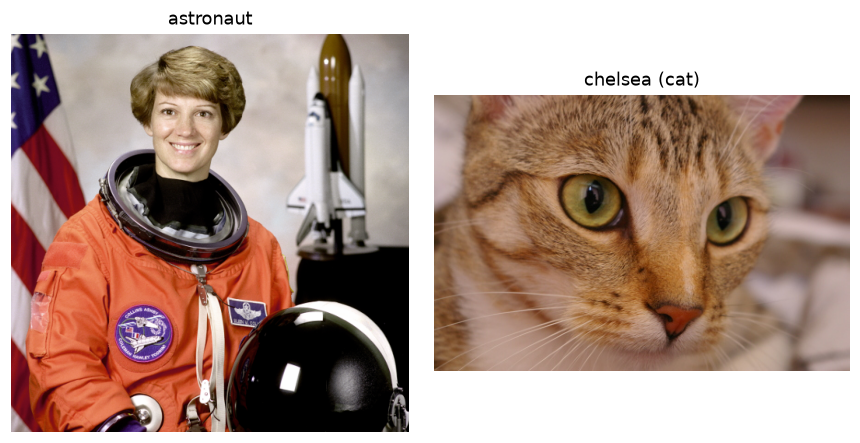

In [2]:
import time
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
print('NumPy :', np.__version__)
print('OpenCV:', cv2.__version__)


def check(name, ok, hint=''):
    # 문제 결과를 알려 주는 도우미: None이면 미작성, True면 통과
    if ok is None:
        print(f'[미작성] {name}: TODO를 채운 뒤 이 셀을 다시 실행하세요.')
    elif ok:
        print(f'[통과] {name}')
    else:
        print(f'[다시 확인] {name}  {hint}')


def same(a, b):
    # 두 배열이 모양·값까지 같은지 (None이면 None)
    if a is None:
        return None
    a = np.asarray(a)
    return a.shape == np.shape(b) and np.array_equal(a, b)


def show(images, titles=None, cols=None, size=3.2, cmap='gray'):
    # 여러 장을 한 줄로 보여 준다. 흑백은 0~255 고정, 컬러는 RGB로 가정
    if not isinstance(images, (list, tuple)):
        images, titles = [images], [titles] if titles else None
    n = len(images)
    cols = cols or n
    rows = (n + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(size * cols, size * rows), squeeze=False)
    for i, ax in enumerate(axes.ravel()):
        ax.axis('off')
        if i >= n:
            continue
        im = images[i]
        if im.ndim == 2:
            ax.imshow(im, cmap=cmap, vmin=0, vmax=255 if im.dtype == np.uint8 else None)
        else:
            ax.imshow(im)
        if titles:
            ax.set_title(titles[i])
    plt.tight_layout()
    plt.show()


def show_grid(img, title=None, size=None):
    # 아주 작은 흑백 이미지를 칸과 숫자, 행·열 번호와 함께 보여 준다
    h, w = img.shape
    size = size or (0.55 * w + 1, 0.55 * h + 0.6)
    fig, ax = plt.subplots(figsize=size)
    ax.imshow(img, cmap='gray', vmin=0, vmax=255)
    for (yy, xx), v in np.ndenumerate(img):
        ax.text(xx, yy, str(int(v)), ha='center', va='center', fontsize=9,
                color='black' if v > 127 else 'white')
    ax.set_xticks(range(w)); ax.set_yticks(range(h))
    ax.set_xlabel('x = column index'); ax.set_ylabel('y = row index')
    ax.xaxis.set_label_position('top'); ax.xaxis.tick_top()
    for k in range(w + 1):
        ax.axvline(k - 0.5, color='0.6', lw=0.6)
    for k in range(h + 1):
        ax.axhline(k - 0.5, color='0.6', lw=0.6)
    if title:
        ax.set_title(title, pad=28)
    plt.tight_layout()
    plt.show()

astro = data.astronaut()      # 우주인 사진 (RGB, 512x512)
cat = data.chelsea()          # 고양이 사진 (RGB, 300x451)
print('astro', astro.shape, '| cat', cat.shape)

REF_HAAR = (177, 66, 95, 95)     # Haar 검출기가 찾은 얼굴 상자 (x, y, w, h)  ← 3회차에서 직접 구함
REF_YUNET = (178, 63, 90, 113)   # YuNet(딥러닝) 상자                         ← 11회차에서 직접 구함
YUNET_EYES = np.array([[200.1, 101.8], [247.1, 102.6]])   # YuNet이 찾은 두 눈 (x, y)
YUNET_MOUTH = np.array([219.2, 143.2])                    # YuNet 입꼬리 두 점의 가운데
show([astro, cat], ['astronaut', 'chelsea (cat)'], size=4)

## 1. 피부색을 숫자로 보기 — 왜 YCrCb인가

RGB의 세 값은 **밝기와 색이 섞여** 있습니다. 같은 얼굴도 그늘에서는 R, G, B가 모두 작아지고 빛을 받으면 모두 커집니다. **YCrCb**는 이를 나눕니다.

- **Y**: 밝기
- **Cr**: 빨강 쪽으로 얼마나 치우쳤나 (128이 중간)
- **Cb**: 파랑 쪽으로 얼마나 치우쳤나 (128이 중간)

사람 피부는 피부색이 밝든 어둡든 **Cr이 조금 높고 Cb가 조금 낮은** 좁은 곳에 모이는 경향이 있습니다. 그래서 Y는 거의 무시하고 Cr, Cb만으로 피부를 고릅니다.

### ✏️ 문제 1 — YCrCb로 바꾸고 채널 나누기

`astro`(RGB)를 YCrCb로 바꾼 `ycc`를 만들고, 세 채널을 각각 `Y`, `Cr`, `Cb`로 꺼내세요. 비교와 계산에 쓰므로 **`float`로** 바꿔 둡니다(2/4: 계산 전에 그릇 키우기).

In [3]:
# >>> TODO q1  (해설본: 정답 채움)
ycc = cv2.cvtColor(astro, cv2.COLOR_RGB2YCrCb)
Y, Cr, Cb = [ycc[..., i].astype(float) for i in range(3)]
# <<< TODO q1

if ycc is None or Cr is None:
    check('문제 1', None)
else:
    ref = cv2.cvtColor(astro, cv2.COLOR_RGB2YCrCb)
    ok = same(ycc, ref) and np.array_equal(Cr, ref[..., 1].astype(float)) and np.array_equal(Cb, ref[..., 2].astype(float)) \
        and Cr.dtype == np.float64
    check('문제 1', ok, hint='cv2.COLOR_RGB2YCrCb (astro는 RGB!), ycc[..., 1].astype(float)')

[통과] 문제 1


아래 셀은 사진 여러 곳의 RGB와 YCrCb 값을 표로 보여 줍니다. **얼굴 세 곳의 RGB는 제각각인데 Cr, Cb는 비슷하다**는 점, 그리고 **배경은 Cr ≈ 133, Cb ≈ 124로 얼굴과 아주 가깝다**는 점을 보세요. 배경이 따뜻한 회색이라 그렇습니다. 이것이 다음 절에서 문제를 일으킵니다.

place                (x, y)           R, G, B         Y, Cr, Cb
face cheek       (230, 140)   [203, 151, 145]   [166, 154, 116]
face forehead     (215, 80)   [186, 147, 115]   [155, 150, 105]
chin             (215, 155)   [233, 194, 179]   [204, 149, 114]
background       (330, 150)   [221, 208, 205]   [212, 134, 124]
background L      (90, 100)   [181, 174, 164]   [175, 132, 122]
suit (orange)    (200, 300)     [207, 94, 56]    [123, 188, 90]
hair              (200, 60)     [100, 73, 22]     [75, 146, 98]


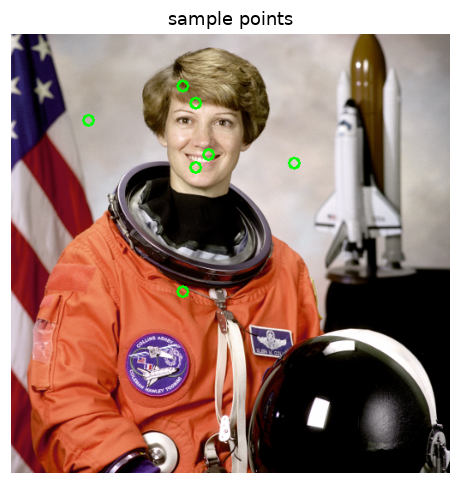

In [4]:
points = {'face cheek': (140, 230), 'face forehead': (80, 215), 'chin': (155, 215),
          'background': (150, 330), 'background L': (100, 90), 'suit (orange)': (300, 200), 'hair': (60, 200)}
ycc_ = cv2.cvtColor(astro, cv2.COLOR_RGB2YCrCb)
print(f"{'place':15s} {'(x, y)':>11s}   {'R, G, B':>15s}   {'Y, Cr, Cb':>15s}")
for name, (yy, xx) in points.items():
    print(f'{name:15s} {str((xx, yy)):>11s}   {str(astro[yy, xx].tolist()):>15s}   {str(ycc_[yy, xx].tolist()):>15s}')
vis = astro.copy()
for name, (yy, xx) in points.items():
    cv2.circle(vis, (xx, yy), 6, (0, 255, 0), 2)          # cv2 함수는 (x, y)!
show([vis], ['sample points'], size=4.5)

## 2. 교과서 범위로 해 보기

널리 인용되는 피부색 범위가 있습니다(Chai & Ngan, 1999).

$$133 \le Cr \le 173, \qquad 77 \le Cb \le 127$$

### ✏️ 문제 2 — 교과서 범위 마스크

위 범위에 드는 픽셀이 True인 `book_mask`(bool)를 만드세요. 비교식 네 개를 `&`로 묶습니다. **비교식마다 괄호!**(3/4)

[통과] 문제 2
피부로 고른 픽셀: 84709 (32.3%)


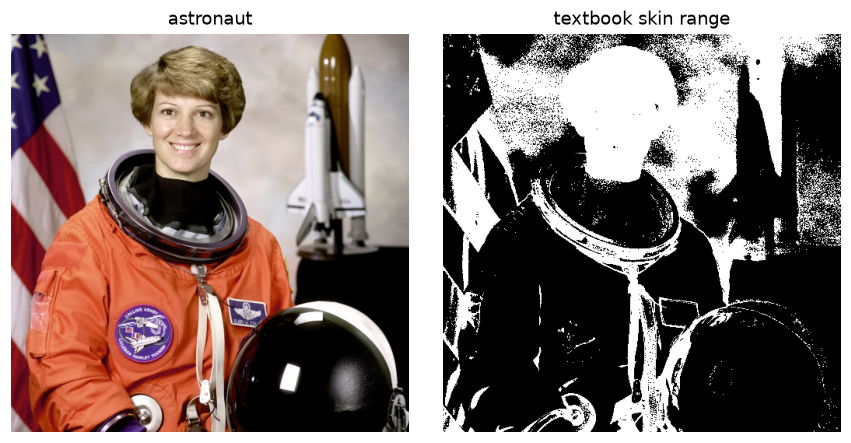

In [5]:
# >>> TODO q2  (해설본: 정답 채움)
book_mask = (Cr >= 133) & (Cr <= 173) & (Cb >= 77) & (Cb <= 127)
# <<< TODO q2

if book_mask is None:
    check('문제 2', None)
else:
    ref = cv2.inRange(cv2.cvtColor(astro, cv2.COLOR_RGB2YCrCb), (0, 133, 77), (255, 173, 127)) > 0
    check('문제 2', same(book_mask, ref), hint='(Cr >= 133) & (Cr <= 173) & (Cb >= 77) & (Cb <= 127)')
    print('피부로 고른 픽셀:', int(book_mask.sum()), f'({book_mask.mean():.1%})')
    show([astro, book_mask.astype(np.uint8) * 255], ['astronaut', 'textbook skin range'], size=4)

얼굴은 잡혔지만 **배경 대부분과 머리카락까지** 피부로 잡힙니다(전체의 약 32%). 교과서 범위는 여러 사람·여러 카메라에 두루 맞추느라 넓게 잡은 범위라서, 이 사진의 따뜻한 회색 배경(Cr ≈ 133)이 경계에 걸렸습니다.

**생각해 보기:** 1회차에서 “사람이 정한 임계값은 다른 환경에서 깨진다”는 것을 봤습니다. 여기서도 같은 일이 일어났습니다. 해결 방법도 1회차와 같습니다. **데이터로 정한다.**

## 3. 데이터로 피부색 범위 정하기

얼굴 안쪽의 작은 사각형(표본 패치)에서 Cr, Cb의 평균과 표준편차를 구해, **평균 ± k × 표준편차**를 범위로 씁니다. 표본에 있는 색과 비슷한 색만 고르는 셈입니다.

$$\text{lo} = \mu - k\sigma, \qquad \text{hi} = \mu + k\sigma$$

### ✏️ 문제 3 — 표본 패치로 범위 계산

`patch = ycc[100:140, 200:240]`(이마~볼, 40×40)에서 Cr과 Cb의 평균·표준편차를 구해 `lo_cr, hi_cr, lo_cb, hi_cb`를 계산하세요. `K = 2`입니다. 패치를 `float`로 바꾼 뒤 채널 축을 골라 `.mean()`, `.std()`를 쓰면 됩니다.

[통과] 문제 3
Cr 141.3 ~ 154.8   |   Cb 103.3 ~ 116.2   (교과서: Cr 133~173, Cb 77~127)


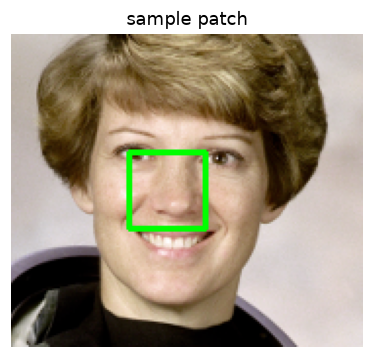

In [6]:
K = 2
# >>> TODO q3  (해설본: 정답 채움)
patch = ycc[100:140, 200:240].astype(float)
mu_cr, sd_cr = patch[..., 1].mean(), patch[..., 1].std()
mu_cb, sd_cb = patch[..., 2].mean(), patch[..., 2].std()
lo_cr, hi_cr = mu_cr - K * sd_cr, mu_cr + K * sd_cr
lo_cb, hi_cb = mu_cb - K * sd_cb, mu_cb + K * sd_cb
# <<< TODO q3

if lo_cr is None:
    check('문제 3', None)
else:
    p = cv2.cvtColor(astro, cv2.COLOR_RGB2YCrCb)[100:140, 200:240].astype(float)
    exp = (p[..., 1].mean() - K * p[..., 1].std(), p[..., 1].mean() + K * p[..., 1].std(),
           p[..., 2].mean() - K * p[..., 2].std(), p[..., 2].mean() + K * p[..., 2].std())
    check('문제 3', np.allclose((lo_cr, hi_cr, lo_cb, hi_cb), exp), hint='patch[..., 1].mean(), patch[..., 1].std()')
    print(f'Cr {lo_cr:.1f} ~ {hi_cr:.1f}   |   Cb {lo_cb:.1f} ~ {hi_cb:.1f}   (교과서: Cr 133~173, Cb 77~127)')
    vis = astro.copy(); cv2.rectangle(vis, (200, 100), (239, 139), (0, 255, 0), 2)
    show([vis[40:200, 140:320]], ['sample patch'], size=3.5)

교과서 범위(폭 40, 50)보다 **훨씬 좁은** 범위(폭 약 14, 13)가 나옵니다. 이 사진, 이 사람, 이 조명에 맞춘 범위입니다. 대신 다른 사진에서는 깨질 수 있습니다(8절에서 확인).

### ✏️ 문제 4 — 학습한 범위로 피부 마스크

`Cr`, `Cb`가 범위 안이고, 너무 어두운 곳(그림자·머리카락)을 빼기 위해 **`Y >= 60`**인 픽셀만 True인 `skin`(bool)을 만드세요. 경계값은 포함(`>=`, `<=`)합니다.

In [7]:
# >>> TODO q4  (해설본: 정답 채움)
skin = (Y >= 60) & (Cr >= lo_cr) & (Cr <= hi_cr) & (Cb >= lo_cb) & (Cb <= hi_cb)
# <<< TODO q4

if skin is None:
    check('문제 4', None)
else:
    exp = (Y >= 60) & (Cr >= lo_cr) & (Cr <= hi_cr) & (Cb >= lo_cb) & (Cb <= hi_cb)
    check('문제 4', same(skin, exp), hint='조건 다섯 개를 &로, 각각 괄호')
    print('피부 픽셀:', int(skin.sum()), f'({skin.mean():.1%})  ← 교과서 범위는 {int(book_mask.sum()) if book_mask is not None else "?"}')

[통과] 문제 4
피부 픽셀: 10460 (4.0%)  ← 교과서 범위는 84709


### 추가 실험 — k를 바꾸면?

k가 크면 범위가 넓어져 얼굴은 더 꽉 차지만 머리카락·배경이 섞이고, k가 작으면 깨끗하지만 구멍이 많아집니다. 1회차의 “놓침 vs 잘못 잡음” 거래와 같습니다.

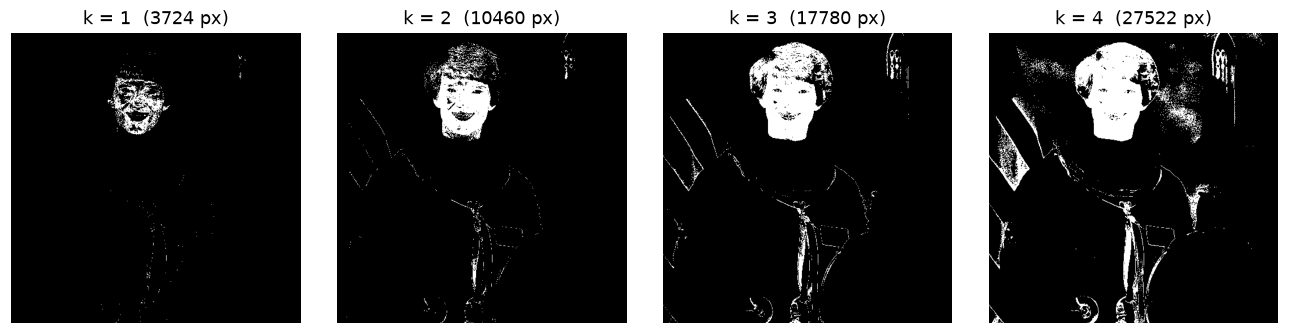

In [8]:
q_ = cv2.cvtColor(astro, cv2.COLOR_RGB2YCrCb).astype(float)      # 문제 1을 안 풀어도 돌아가도록 따로 계산
p = q_[100:140, 200:240]
masks, titles = [], []
for k in (1, 2, 3, 4):
    m = (q_[..., 0] >= 60) & (np.abs(q_[..., 1] - p[..., 1].mean()) <= k * p[..., 1].std()) \
        & (np.abs(q_[..., 2] - p[..., 2].mean()) <= k * p[..., 2].std())
    masks.append(m.astype(np.uint8) * 255); titles.append(f'k = {k}  ({int(m.sum())} px)')
show(masks, titles, size=3)

## 4. 잡음 정리와 얼굴 덩어리 고르기

마스크에는 작은 점(잡음)과 구멍이 있습니다. **모폴로지 연산**으로 정리합니다(코드는 주어짐).

- **열림(open)**: 작은 흰 점 지우기 — 깎았다가(침식) 다시 불리기(팽창)
- **닫힘(close)**: 작은 검은 틈 메우기 — 불렸다가 다시 깎기

그다음 **연결 요소(connected components)**: 서로 붙어 있는 흰 픽셀끼리 같은 번호(label)를 붙입니다. `stats[i]`에는 i번 덩어리의 `x, y, w, h, 넓이`가 들어 있고, **0번은 배경**입니다.

덩어리 수(배경 포함): 3
넓이 상위 5개 [x, y, w, h, area]:
  label 2 [ 172   78   99  102 6697]
  label 1 [192  63   7   7  33]


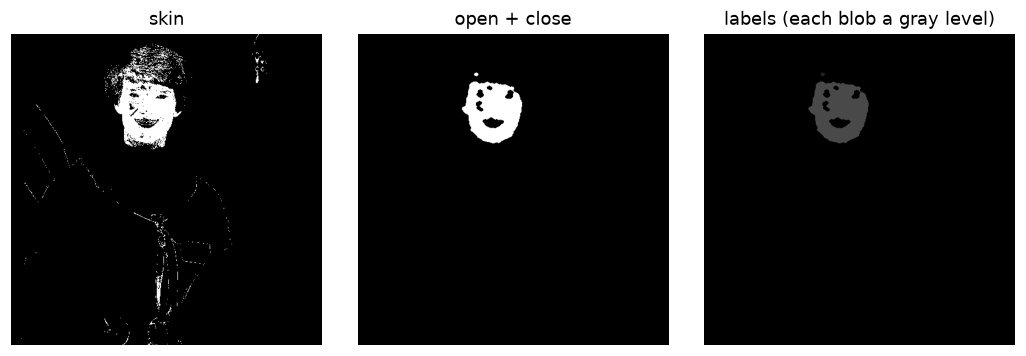

In [9]:
skin_u8 = (skin if skin is not None else np.zeros(astro.shape[:2], bool)).astype(np.uint8)
ker = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
clean = cv2.morphologyEx(skin_u8, cv2.MORPH_OPEN, ker)
clean = cv2.morphologyEx(clean, cv2.MORPH_CLOSE, ker)
n_lab, labels, stats, cents = cv2.connectedComponentsWithStats(clean)
print('덩어리 수(배경 포함):', n_lab)
print('넓이 상위 5개 [x, y, w, h, area]:')
for i in (1 + np.argsort(-stats[1:, cv2.CC_STAT_AREA]))[:5]:
    print('  label', i, stats[i])
show([skin_u8 * 255, clean * 255, (labels * 37 % 256).astype(np.uint8)], ['skin', 'open + close', 'labels (each blob a gray level)'], size=3.2)

### ✏️ 문제 5 — 가장 큰 덩어리 = 얼굴, 그리고 바운딩 박스

1. 배경(0번)을 뺀 덩어리 중 **넓이가 가장 큰** 번호 `face_label`을 구하세요. `stats[1:, cv2.CC_STAT_AREA]`에서 `argmax`를 하면 0부터 다시 세므로 **1을 더해야** 합니다(4/4 문제 9와 같은 함정).
2. `face = (labels == face_label)`로 얼굴 마스크를 만들고,
3. `np.nonzero`로 바운딩 박스 `face_box = (x, y, w, h)`를 구하세요. **y가 먼저, +1 잊지 말기**(3/4).

In [10]:
# >>> TODO q5  (해설본: 정답 채움)
face_label = 1 + int(np.argmax(stats[1:, cv2.CC_STAT_AREA]))
face = labels == face_label
ys, xs = np.nonzero(face)
face_box = (xs.min(), ys.min(), xs.max() - xs.min() + 1, ys.max() - ys.min() + 1)
# <<< TODO q5

if face_box is None:
    check('문제 5', None)
else:
    i_ = 1 + int(np.argmax(stats[1:, cv2.CC_STAT_AREA]))
    ys_, xs_ = np.nonzero(labels == i_)
    exp = (xs_.min(), ys_.min(), xs_.max() - xs_.min() + 1, ys_.max() - ys_.min() + 1)
    check('문제 5', tuple(int(v) for v in face_box) == tuple(int(v) for v in exp),
          hint=f'기대 {tuple(int(v) for v in exp)}. 1 더하기, (ys, xs) 순서, +1 확인')
    print('face_box =', tuple(int(v) for v in face_box))

[통과] 문제 5
face_box = (172, 78, 99, 102)


## 5. 검출기와 비교 — 상자 IoU

3/4에서는 마스크끼리 IoU를 구했습니다. 상자끼리는 **겹친 사각형**을 직접 계산합니다.

- 겹친 사각형의 왼쪽 = 두 왼쪽 중 큰 값, 오른쪽 = 두 오른쪽(`x + w`) 중 작은 값
- 겹친 너비 = `max(0, 오른쪽 − 왼쪽)` (안 겹치면 0), 높이도 같은 방식
- $\text{IoU} = \dfrac{\text{겹친 넓이}}{\text{A 넓이} + \text{B 넓이} - \text{겹친 넓이}}$

### ✏️ 문제 6 — `box_iou(A, B)`

[통과] 문제 6
IoU(색 기반, Haar)  = 0.69
IoU(색 기반, YuNet) = 0.77


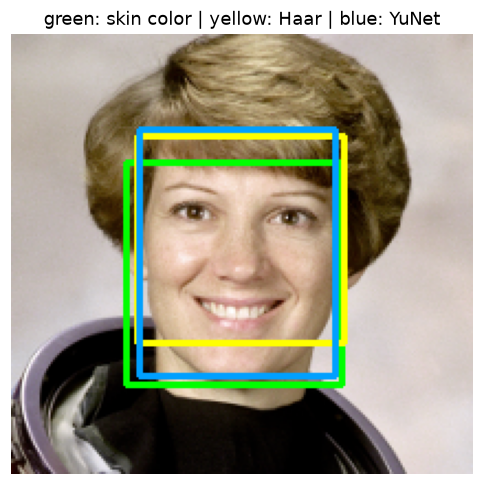

In [11]:
def box_iou(A, B):
    ax, ay, aw, ah = A
    bx, by, bw, bh = B
    # >>> TODO q6  (해설본: 정답 채움)
    iw = max(0, min(ax + aw, bx + bw) - max(ax, bx))
    ih = max(0, min(ay + ah, by + bh) - max(ay, by))
    inter = iw * ih
    return inter / (aw * ah + bw * bh - inter)
    # <<< TODO q6

tests = [((0, 0, 10, 10), (0, 0, 10, 10), 1.0), ((0, 0, 10, 10), (5, 0, 10, 10), 50 / 150),
         ((0, 0, 10, 10), (20, 20, 5, 5), 0.0), ((0, 0, 4, 4), (1, 1, 2, 2), 4 / 16)]
if box_iou((0, 0, 1, 1), (0, 0, 1, 1)) is None:
    check('문제 6', None)
else:
    bad = [t[:2] for t in tests if not np.isclose(box_iou(t[0], t[1]), t[2])]
    check('문제 6', not bad, hint=f'틀린 경우: {bad[:2]}. 안 겹칠 때 max(0, …)')
    if face_box is not None:
        print(f'IoU(색 기반, Haar)  = {box_iou(face_box, REF_HAAR):.2f}')
        print(f'IoU(색 기반, YuNet) = {box_iou(face_box, REF_YUNET):.2f}')
        vis = astro.copy()
        for (bx_, by_, bw_, bh_), col in ((face_box, (0, 255, 0)), (REF_HAAR, (255, 255, 0)), (REF_YUNET, (0, 160, 255))):
            cv2.rectangle(vis, (int(bx_), int(by_)), (int(bx_ + bw_ - 1), int(by_ + bh_ - 1)), col, 2)
        show([vis[20:220, 120:330]], ['green: skin color | yellow: Haar | blue: YuNet'], size=4.5)

학습 없이 색만으로 IoU 0.7 안팎이 나옵니다. 색 기반 상자는 **이마 위 머리카락 경계부터 턱까지 피부가 보이는 곳**을 감싸고, 검출기 상자는 학습 데이터에서 정한 ‘얼굴’ 기준(눈썹~턱 등)을 따르므로 조금 다릅니다. 둘 중 무엇이 ‘정답’인지는 정의하기 나름입니다.

## 6. 고양이 얼굴 붙이기 — 첫 번째 버전

고양이 사진에서 얼굴 부분 `cat[10:300, 60:400]`을 잘라, 우리 얼굴 상자 크기로 줄여서 그 자리에 붙입니다.

**함정:** `cv2.resize(img, (w, h))`의 크기 인자는 **(너비, 높이)**입니다. 결과의 `shape`은 `(h, w, 3)`입니다(1/4: 배열은 행 먼저, OpenCV 함수는 가로 먼저).

### ✏️ 문제 7 — 크기 맞춰 붙이기

1. `small`: `cat_face`를 `face_box`의 크기로 줄인 것 (`interpolation=cv2.INTER_AREA`는 축소에 좋은 방식)
2. `pasted`: `astro`의 **복사본**에서 얼굴 상자 자리에 `small`을 붙인 결과

[통과] 문제 7


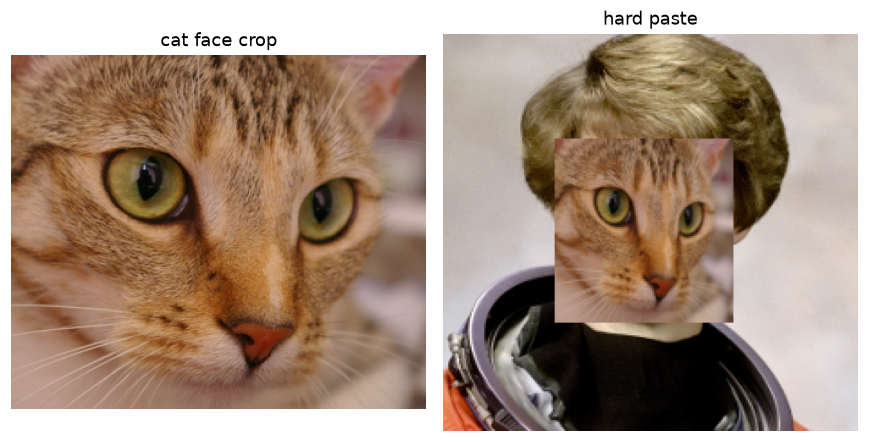

In [12]:
cat_face = cat[10:300, 60:400]          # 고양이 얼굴 부분 (290 x 340)
x, y, w, h = [int(v) for v in (face_box if face_box is not None else REF_HAAR)]
# >>> TODO q7  (해설본: 정답 채움)
small = cv2.resize(cat_face, (w, h), interpolation=cv2.INTER_AREA)
pasted = astro.copy()
pasted[y:y + h, x:x + w] = small
# <<< TODO q7

if pasted is None:
    check('문제 7', None)
else:
    ok = small.shape == (h, w, 3) and np.array_equal(pasted[y:y + h, x:x + w], small) \
        and np.array_equal(pasted[:y], astro[:y]) and not np.shares_memory(pasted, astro)
    check('문제 7', ok, hint='cv2.resize(cat_face, (w, h)) → shape (h, w, 3). astro.copy()에 붙이기')
    show([cat_face, pasted[20:240, 110:340]], ['cat face crop', 'hard paste'], size=4)

붙기는 했지만 **네모난 경계**가 그대로 보이고, 고양이 눈과 사람 눈의 위치도 맞지 않습니다. 다음 절에서 경계를, ⭐ 8절에서 눈 위치를 해결합니다.

## 7. 자연스럽게 섞기 — 타원 마스크와 알파 블렌딩

1. 얼굴 덩어리의 윤곽에 **타원을 맞춥니다**(`cv2.fitEllipse`, 코드 주어짐). 피부 마스크의 구멍(눈·입)이나 울퉁불퉁한 가장자리와 상관없이 매끈한 얼굴 모양이 됩니다.
2. 타원 안 = 1, 밖 = 0인 마스크를 **가우시안 블러로 흐리게** 하면, 가장자리에서 1 → 0으로 부드럽게 변하는 `alpha`가 됩니다(4/4: 블러 = 이웃 평균).
3. 픽셀마다 섞기:

$$\text{out} = \alpha \cdot \text{고양이} + (1 - \alpha) \cdot \text{원본}$$

`alpha`는 `(H, W)`, 사진은 `(H, W, 3)`이므로 `alpha[..., None]`로 채널 축을 붙입니다(3/4 컬러 스플래시와 같음). 계산은 `float`로, 마지막에 `round` → `uint8`(2/4).

타원 중심 (222.4, 126.0), 축 길이 (92.9, 103.4), 각도 160.2
alpha float32 (512, 512) 범위 0.00 ~ 1.00


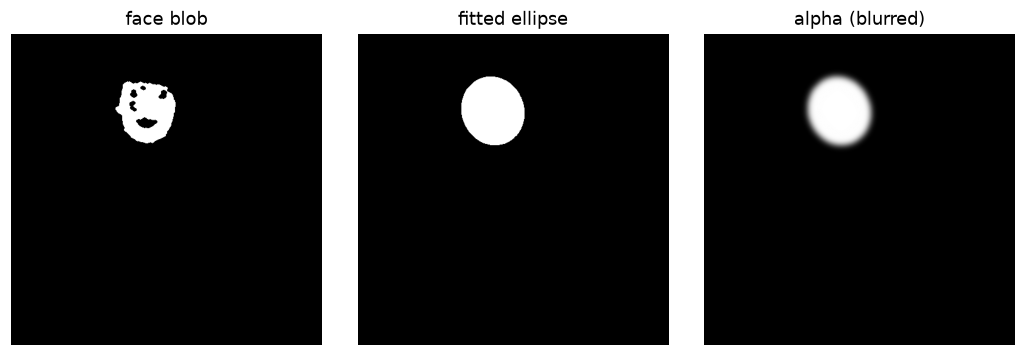

In [13]:
face_u8 = (face if face is not None else np.zeros(astro.shape[:2], bool)).astype(np.uint8)
cnts, _ = cv2.findContours(face_u8, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
if cnts:
    (ecx, ecy), (ea, eb), eang = cv2.fitEllipse(max(cnts, key=cv2.contourArea))
else:
    (ecx, ecy), (ea, eb), eang = (224.0, 113.0), (95.0, 113.0), 0.0
print(f'타원 중심 ({ecx:.1f}, {ecy:.1f}), 축 길이 ({ea:.1f}, {eb:.1f}), 각도 {eang:.1f}')
ell = np.zeros(astro.shape[:2], np.float32)
cv2.ellipse(ell, ((ecx, ecy), (ea * 1.1, eb * 1.1), eang), 1.0, -1)     # 10% 크게
alpha = cv2.GaussianBlur(ell, (0, 0), 5)                                  # 0~1, 가장자리만 부드럽게
cat_big = np.zeros_like(astro)                                            # 고양이를 사진 크기 캔버스에
if small is not None:
    cat_big[y:y + h, x:x + w] = small
print('alpha', alpha.dtype, alpha.shape, f'범위 {alpha.min():.2f} ~ {alpha.max():.2f}')
show([face_u8 * 255, (ell * 255).astype(np.uint8), (alpha * 255).astype(np.uint8)], ['face blob', 'fitted ellipse', 'alpha (blurred)'], size=3.2)

### ✏️ 문제 8 — 알파 블렌딩

`cat_big`과 `astro`를 `alpha`로 섞은 `blend`(`uint8`)를 만드세요.

[통과] 문제 8


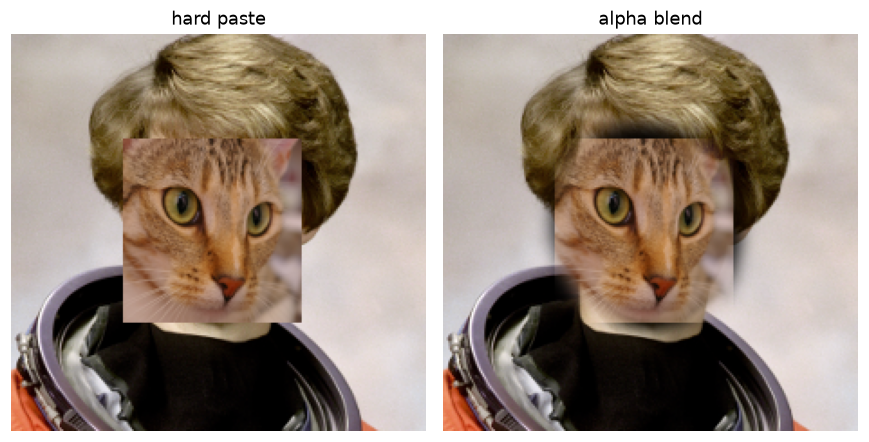

In [14]:
# >>> TODO q8  (해설본: 정답 채움)
a3 = alpha[..., None]
blend = np.round(a3 * cat_big + (1 - a3) * astro).astype(np.uint8)
# <<< TODO q8

if blend is None:
    check('문제 8', None)
else:
    a3 = alpha[..., None]
    exp = np.round(a3 * cat_big + (1 - a3) * astro).astype(np.uint8)
    check('문제 8', same(blend, exp), hint='alpha[..., None] * cat_big + (1 - alpha[..., None]) * astro → np.round → astype(np.uint8)')
    show([pasted[20:240, 110:340] if pasted is not None else astro, blend[20:240, 110:340]], ['hard paste', 'alpha blend'], size=4)

## 8. ⭐ 눈 위치 맞추기 — 마스크의 구멍이 눈과 입이다

피부 마스크에서 얼굴 덩어리에는 **구멍**이 있습니다. 눈과 입은 피부색이 아니기 때문입니다. 얼굴 상자 안에서 마스크를 뒤집으면(`~`) 구멍이 흰 덩어리가 되고, 다시 연결 요소를 구하면 각 구멍의 중심을 얻습니다.

- 상자 가장자리에 닿는 덩어리(`touch`)는 구멍이 아니라 얼굴 **바깥**이므로 뺍니다.
- **눈**: 위쪽 35% 안에 있는 구멍 중 가장 큰 두 개 (왼쪽부터 정렬)
- **입**: 아래쪽 절반에 있는 구멍 중 가장 큰 것

> 이런 규칙은 이 사진에 맞춘 **사람의 손규칙**입니다. 안경, 앞머리, 옆얼굴에서는 바로 깨집니다. 학습 기반 검출기가 하는 일이 바로 이런 규칙을 데이터로 배우는 것입니다.

구멍  0: 중심 ( 176.8,   94.7)  넓이  406  가장자리에 닿음
구멍  1: 중심 ( 193.0,   78.0)  넓이    1  가장자리에 닿음
구멍  2: 중심 ( 203.8,   78.8)  넓이   40  가장자리에 닿음
구멍  3: 중심 ( 254.8,   85.7)  넓이  513  가장자리에 닿음
구멍  4: 중심 ( 217.0,   88.4)  넓이   48  
구멍  5: 중심 ( 201.6,   97.9)  넓이  115  
구멍  6: 중심 ( 250.1,   99.5)  넓이  143  
구멍  7: 중심 ( 200.1,  118.3)  넓이  128  
구멍  8: 중심 ( 260.4,  164.0)  넓이  661  가장자리에 닿음
구멍  9: 중심 ( 183.4,  161.1)  넓이  939  가장자리에 닿음
구멍 10: 중심 ( 222.4,  145.8)  넓이  400  
구멍 11: 중심 ( 228.6,  178.9)  넓이    7  가장자리에 닿음


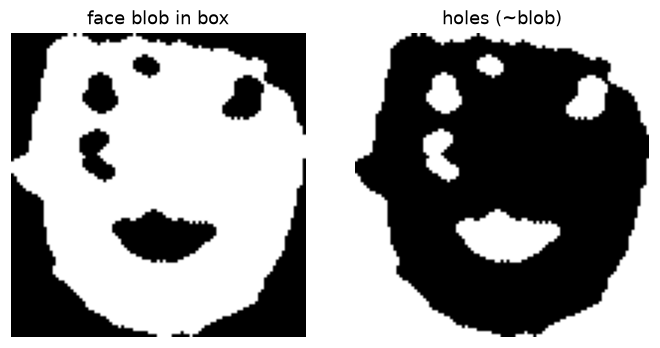

In [15]:
sub = face[y:y + h, x:x + w] if face is not None else np.ones((h, w), bool)
holes = (~sub).astype(np.uint8)
nh, hlab, hst, hcen = cv2.connectedComponentsWithStats(holes)
hx, hy, hw, hh, harea = [hst[1:, i] for i in range(5)]           # 0번(배경) 제외
hcx, hcy = hcen[1:, 0] + x, hcen[1:, 1] + y                       # 상자 좌표 → 사진 좌표
touch = (hx == 0) | (hy == 0) | (hx + hw == w) | (hy + hh == h)
for i in range(len(harea)):
    print(f'구멍 {i:2d}: 중심 ({hcx[i]:6.1f}, {hcy[i]:6.1f})  넓이 {harea[i]:4d}  {"가장자리에 닿음" if touch[i] else ""}')
show([(sub * 255).astype(np.uint8), holes * 255], ['face blob in box', 'holes (~blob)'], size=3.2)

### ✏️ ⭐ 문제 9 — 눈 두 개와 입 고르기

배열 `hcx, hcy, harea, touch`(모두 길이가 같은 1차원)에서 위 규칙대로 골라 `eyes`(2×2 배열, `[[왼눈 x, y], [오른눈 x, y]]`)와 `mouth`(길이 2 배열 `[x, y]`)를 만드세요.

힌트: `cand = np.nonzero((~touch) & (hcy < y + 0.35 * h))[0]`는 조건을 만족하는 구멍 번호들입니다. 그중 `harea`가 큰 두 개 → `hcx` 순으로 정렬.

[통과] 문제 9
내가 찾은 눈 [[201.6, 97.9], [250.1, 99.5]] 입 [222.4, 145.8]
YuNet       눈 [[200.1, 101.8], [247.1, 102.6]] 입 [219.2, 143.2]


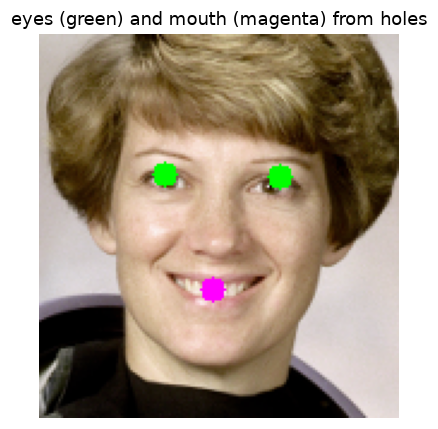

In [16]:
# >>> TODO q9  (해설본: 정답 채움)
cand = np.nonzero((~touch) & (hcy < y + 0.35 * h))[0]
two = cand[np.argsort(harea[cand])[-2:]]          # 넓이가 큰 두 개
two = two[np.argsort(hcx[two])]                   # 왼쪽부터
eyes = np.stack([hcx[two], hcy[two]], axis=1)
low = np.nonzero((~touch) & (hcy > y + 0.5 * h))[0]
j = low[np.argmax(harea[low])]
mouth = np.array([hcx[j], hcy[j]])
# <<< TODO q9

if eyes is None or mouth is None:
    check('문제 9', None)
else:
    d_eye = np.linalg.norm(np.asarray(eyes) - YUNET_EYES, axis=1)
    d_mouth = np.linalg.norm(np.asarray(mouth) - YUNET_MOUTH)
    check('문제 9', np.asarray(eyes).shape == (2, 2) and d_eye.max() < 8 and d_mouth < 8,
          hint=f'YuNet과의 거리: 눈 {np.round(d_eye, 1)}, 입 {d_mouth:.1f}. 왼눈이 먼저인지 확인')
    print('내가 찾은 눈', np.round(eyes, 1).tolist(), '입', np.round(mouth, 1).tolist())
    print('YuNet       눈', YUNET_EYES.tolist(), '입', YUNET_MOUTH.tolist())
    vis = astro.copy()
    for (px, py) in np.asarray(eyes):
        cv2.circle(vis, (int(round(px)), int(round(py))), 5, (0, 255, 0), -1)
    cv2.circle(vis, (int(round(mouth[0])), int(round(mouth[1]))), 5, (255, 0, 255), -1)
    show([vis[40:200, 150:300]], ['eyes (green) and mouth (magenta) from holes'], size=4)

### 고양이 눈을 사람 눈에 맞추기 — 닮음 변환

고양이 사진에서 두 눈과 입의 위치는 미리 재 두었습니다. 세 점 쌍으로 **회전 + 크기 + 이동**(닮음 변환)을 구하는 함수가 `cv2.estimateAffinePartial2D`이고, 그 변환으로 고양이 사진 전체를 옮기는 함수가 `cv2.warpAffine`입니다. 결과는 2×3 행렬 `M`이며, 점 `(x, y)`는 `M @ [x, y, 1]`로 옮겨집니다.

**주의:** 고양이 사진 바깥(특히 입 아래쪽)은 옮긴 뒤 빈 곳이 됩니다. 그래서 ‘고양이 사진이 실제로 있는 곳’ 마스크 `valid`도 같이 옮겨서 알파에 곱합니다(마스크끼리 곱하기 = `&`). 또 옮긴 사진의 빈 곳을 검정(0)으로 두면 알파를 흐릴 때 검은 띠가 섞이므로, `BORDER_REPLICATE`로 가장자리 색을 늘려 채웁니다(4/4 패딩의 `edge` 방식과 같음).

M =
 [[ 3.27000e-01  3.40000e-02  1.41373e+02]
 [-3.40000e-02  3.27000e-01  6.60720e+01]]
크기 배율 ≈ 0.329


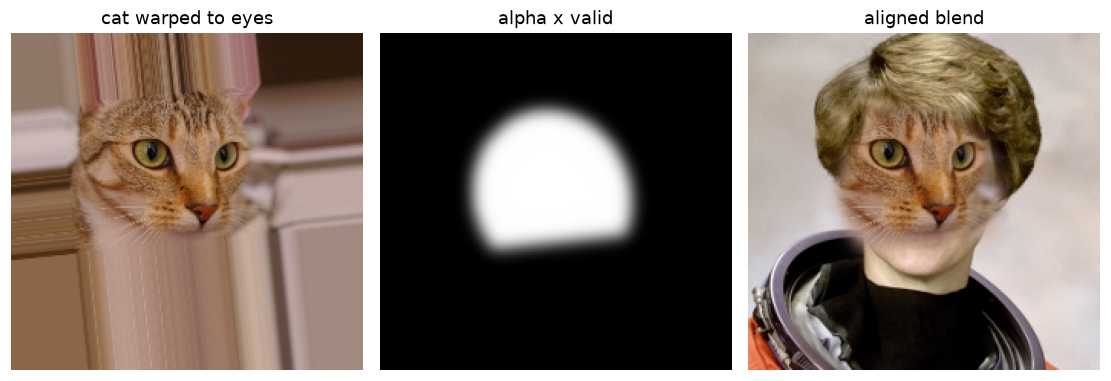

In [17]:
CAT_PTS = np.float32([[172, 115], [318, 135], [258, 262]])       # 고양이: 왼눈, 오른눈, 입 (x, y)
if eyes is not None and mouth is not None:
    dst = np.float32([eyes[0], eyes[1], mouth])
else:
    dst = np.float32([YUNET_EYES[0], YUNET_EYES[1], YUNET_MOUTH])
M, _ = cv2.estimateAffinePartial2D(CAT_PTS, dst)
print('M =\n', np.round(M, 3))
print('크기 배율 ≈', round(float(np.hypot(M[0, 0], M[1, 0])), 3))
warped = cv2.warpAffine(cat, M, (512, 512), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REPLICATE)   # 바깥을 검정 대신 가장자리 색으로
valid = cv2.warpAffine(np.ones(cat.shape[:2], np.float32), M, (512, 512))     # 고양이가 있는 곳 = 1
alpha2 = cv2.GaussianBlur(ell * valid, (0, 0), 5)
a3 = alpha2[..., None]
aligned = np.round(a3 * warped + (1 - a3) * astro).astype(np.uint8)
show([warped[20:240, 110:340], (alpha2 * 255).astype(np.uint8)[20:240, 110:340], aligned[20:240, 110:340]],
     ['cat warped to eyes', 'alpha x valid', 'aligned blend'], size=3.4)

### ✏️ ⭐ 문제 10 — 피부 톤 맞추기 (색 보정)

고양이 털색과 사람 얼굴색이 달라 경계가 티 납니다. **타원 안에서** 채널마다 평균 밝기를 사람 얼굴과 같게 맞춰 봅니다.

$$\text{tuned}_c = \text{warped}_c + \big(\text{mean}(\text{astro}_c[\text{in}]) - \text{mean}(\text{warped}_c[\text{in}])\big)$$

`inside = ell > 0`인 마스크를 쓰고, `float`로 계산한 뒤 0~255로 잘라 `uint8`로 만든 `tuned`를 만드세요. 그다음 `alpha2`로 섞은 `final`을 만드세요.

[통과] 문제 10


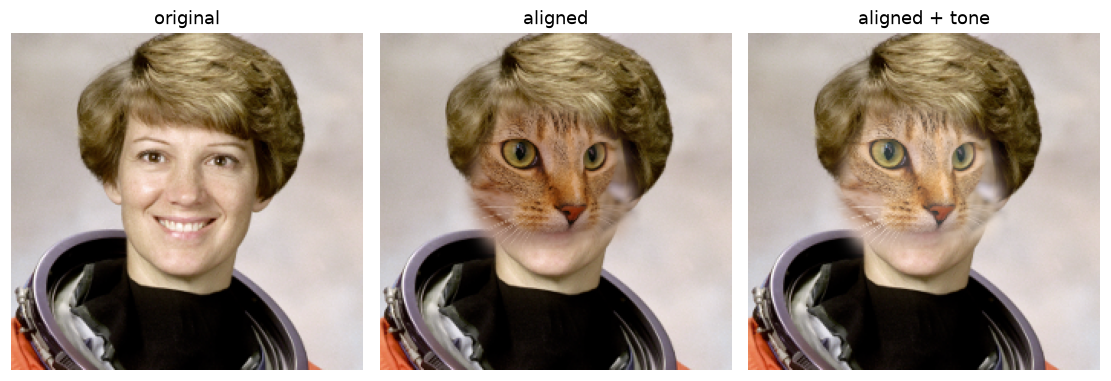

In [18]:
inside = ell > 0
# >>> TODO q10  (해설본: 정답 채움)
tuned = warped.astype(float)
for c in range(3):
    tuned[..., c] += astro[..., c][inside].mean() - warped[..., c][inside].mean()
tuned = np.clip(tuned, 0, 255).astype(np.uint8)
final = np.round(a3 * tuned + (1 - a3) * astro).astype(np.uint8)
# <<< TODO q10

if tuned is None or final is None:
    check('문제 10', None)
else:
    t = warped.astype(float)
    for c in range(3):
        t[..., c] += astro[..., c][inside].mean() - warped[..., c][inside].mean()
    t = np.clip(t, 0, 255).astype(np.uint8)
    f = np.round(a3 * t + (1 - a3) * astro).astype(np.uint8)
    ok = same(tuned, t) and np.abs(final.astype(int) - f).max() <= 1
    check('문제 10', ok, hint='채널마다 warped[..., c][inside].mean(), clip 후 uint8')
    show([astro[20:240, 110:340], aligned[20:240, 110:340], final[20:240, 110:340]], ['original', 'aligned', 'aligned + tone'], size=3.4)

## 9. 추가 실험 — 곰 스티커 (그려서 만든 동물)

동물 사진이 없어도 됩니다. `cv2.circle`, `cv2.ellipse`로 곰 얼굴을 그리고, **그린 곳 = 1인 알파 채널**을 함께 만들면 스티커가 됩니다. 붙이는 방법은 7절과 같습니다. 크기는 얼굴 상자 너비의 1.5배, 곰 얼굴 중심을 사람 얼굴 타원 중심에 맞춥니다.

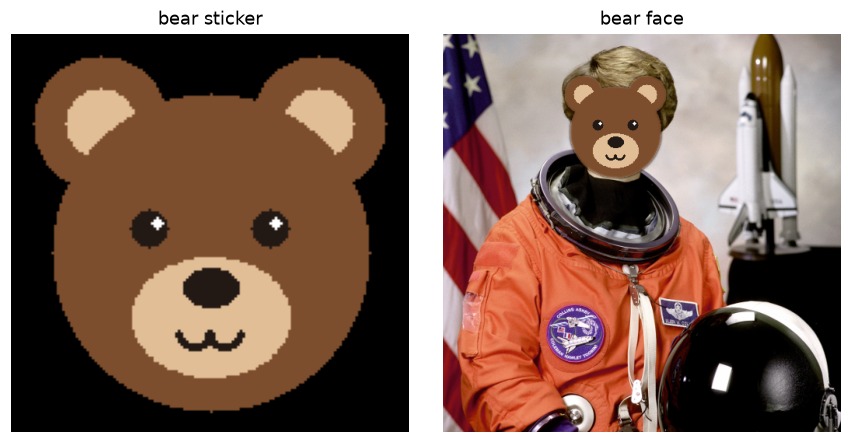

In [19]:
def make_bear(size=200):
    rgb = np.zeros((size, size, 3), np.uint8)
    a = np.zeros((size, size), np.uint8)
    s = size / 200
    P = lambda px, py: (int(px * s), int(py * s))
    R = lambda r: int(r * s)
    brown, light, dark = (125, 78, 45), (225, 190, 150), (35, 25, 20)
    for cx_ in (45, 155):                                         # 귀
        cv2.circle(rgb, P(cx_, 45), R(35), brown, -1); cv2.circle(a, P(cx_, 45), R(35), 255, -1)
        cv2.circle(rgb, P(cx_, 45), R(18), light, -1)
    cv2.circle(rgb, P(100, 110), R(80), brown, -1); cv2.circle(a, P(100, 110), R(80), 255, -1)   # 얼굴
    cv2.ellipse(rgb, P(100, 142), (R(40), R(30)), 0, 0, 360, light, -1)                         # 주둥이
    for cx_ in (70, 130):
        cv2.circle(rgb, P(cx_, 98), R(10), dark, -1); cv2.circle(rgb, P(cx_ + 3, 95), R(3), (255, 255, 255), -1)
    cv2.ellipse(rgb, P(100, 128), (R(14), R(10)), 0, 0, 360, dark, -1)                          # 코
    cv2.ellipse(rgb, P(92, 150), (R(9), R(7)), 0, 0, 180, dark, R(3))                           # 입
    cv2.ellipse(rgb, P(108, 150), (R(9), R(7)), 0, 0, 180, dark, R(3))
    return rgb, a.astype(np.float32) / 255

size = int(1.5 * w)
bear, bear_a = make_bear(size)
bx0 = int(round(ecx - 100 * size / 200))            # 곰 얼굴 중심 (100, 110)을 사람 얼굴 중심에
by0 = int(round(ecy - 110 * size / 200))
canvas, canvas_a = np.zeros_like(astro), np.zeros(astro.shape[:2], np.float32)
canvas[by0:by0 + size, bx0:bx0 + size] = bear
canvas_a[by0:by0 + size, bx0:bx0 + size] = cv2.GaussianBlur(bear_a, (0, 0), 1.5)
ab = canvas_a[..., None]
bear_out = np.round(ab * canvas + (1 - ab) * astro).astype(np.uint8)
show([bear, bear_out], ['bear sticker', 'bear face'], size=4)

**확인해 볼 것:** 사람 얼굴이 사진 가장자리 가까이 있으면 `by0`가 음수가 되거나 `by0 + size`가 512를 넘어 붙이기가 실패합니다(1/4: 범위 밖 슬라이스는 잘려서 크기가 안 맞음). 과제 3번에서 잘리는 부분을 처리해 보세요.

## 10. 다른 사진에서도 될까? — 색 기반 방법의 한계

지금까지의 과정을 함수 하나로 묶고(**피부색 범위는 우주인 사진에서 배운 값 그대로**), 조금씩 바꾼 사진에 적용해 봅니다.

original        box = (172, 78, 99, 102)
flipped         box = (241, 78, 99, 102)
rotated 20 deg  box = (127, 92, 105, 110)
half size       box = (86, 38, 50, 52)
brighter +40    box = (170, 79, 101, 101)
darker x0.7     box = (215, 117, 39, 21)


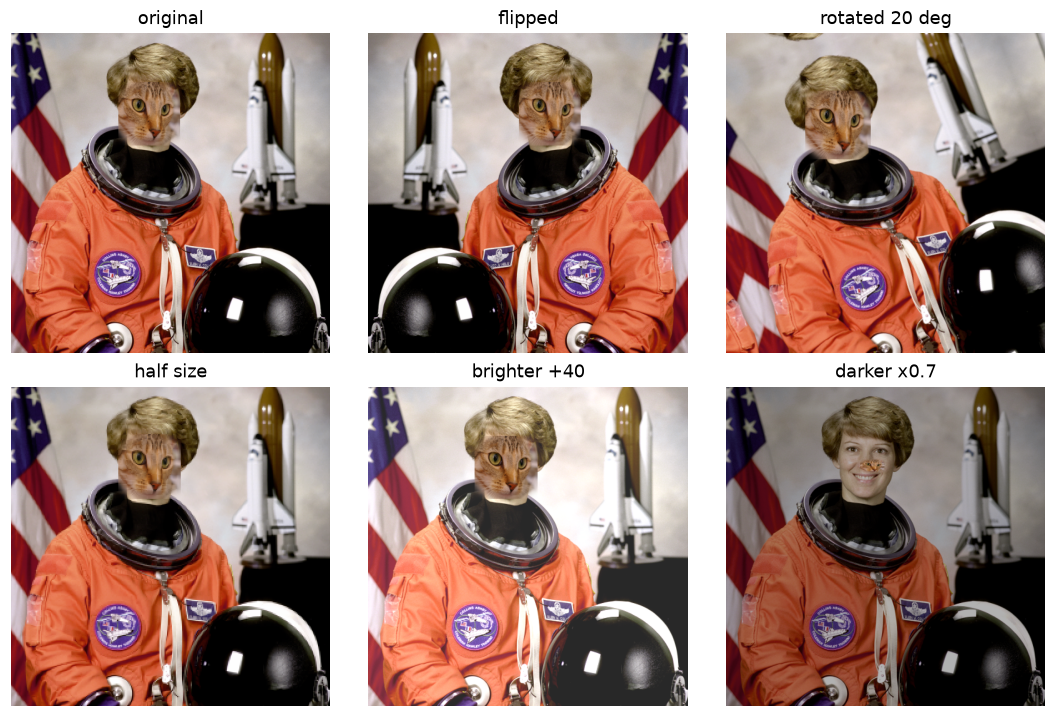

In [20]:
SKIN = (lo_cr, hi_cr, lo_cb, hi_cb) if lo_cr is not None else (141.3, 154.8, 103.3, 116.2)

def find_face_box(img, skin_range=SKIN, y_min=60):
    lcr, hcr, lcb, hcb = skin_range
    q = cv2.cvtColor(img, cv2.COLOR_RGB2YCrCb).astype(float)
    m = ((q[..., 0] >= y_min) & (q[..., 1] >= lcr) & (q[..., 1] <= hcr) & (q[..., 2] >= lcb) & (q[..., 2] <= hcb)).astype(np.uint8)
    m = cv2.morphologyEx(cv2.morphologyEx(m, cv2.MORPH_OPEN, ker), cv2.MORPH_CLOSE, ker)
    n_, lab_, st_, _ = cv2.connectedComponentsWithStats(m)
    if n_ < 2:
        return None
    i_ = 1 + int(np.argmax(st_[1:, cv2.CC_STAT_AREA]))
    return tuple(int(v) for v in st_[i_, :4])               # stats에 이미 (x, y, w, h)가 들어 있다

def cat_swap(img, box):
    if box is None:
        return img.copy()
    bx_, by_, bw_, bh_ = box
    out = img.astype(float)
    sm = cv2.resize(cat_face, (bw_, bh_), interpolation=cv2.INTER_AREA).astype(float)
    e = np.zeros(img.shape[:2], np.float32)
    cv2.ellipse(e, (bx_ + bw_ // 2, by_ + bh_ // 2), (int(bw_ * 0.55), int(bh_ * 0.55)), 0, 0, 360, 1.0, -1)
    al = cv2.GaussianBlur(e, (0, 0), max(1, bw_ / 20))[by_:by_ + bh_, bx_:bx_ + bw_, None]
    out[by_:by_ + bh_, bx_:bx_ + bw_] = al * sm + (1 - al) * out[by_:by_ + bh_, bx_:bx_ + bw_]
    return np.round(out).astype(np.uint8)

variants = {
    'original': astro,
    'flipped': astro[:, ::-1],
    'rotated 20 deg': cv2.warpAffine(astro, cv2.getRotationMatrix2D((256, 256), 20, 1), (512, 512), borderMode=cv2.BORDER_REFLECT),
    'half size': cv2.resize(astro, (256, 256), interpolation=cv2.INTER_AREA),
    'brighter +40': np.clip(astro.astype(int) + 40, 0, 255).astype(np.uint8),
    'darker x0.7': np.clip(astro * 0.7, 0, 255).astype(np.uint8),
}
outs, titles = [], []
for name, im in variants.items():
    b = find_face_box(im)
    print(f'{name:15s} box = {b}')
    outs.append(cat_swap(im, b)); titles.append(name)
show(outs, titles, cols=3, size=3.3)

**관찰**

- 좌우 반전, 회전, 크기 변화에는 잘 버팁니다. 색은 위치·방향·크기와 상관없기 때문입니다.
- **어둡게(×0.7)** 하면 무너집니다. RGB를 0.7배 하면 Cr, Cb도 128 쪽으로 0.7배 당겨져(예: Cr 148 → 142) 배운 범위에서 벗어납니다. 1회차 도로 영상의 조명 문제와 같은 원인입니다.
- 사진에 사람이 둘이거나, 손·팔이 크게 나오거나, 나무색 가구처럼 피부와 비슷한 색이 많으면 “가장 큰 덩어리 = 얼굴” 규칙이 깨집니다.

색은 **빠르고 단순한 단서**지만, ‘얼굴’이라는 **모양**은 모릅니다. 다음 회차의 Haar(Viola–Jones)는 명암 모양으로, 11회차의 YuNet은 학습한 특징으로 이 문제를 풉니다.

In [21]:
# (선택) 내 사진으로 해 보기: 같은 폴더에 사진을 두고 이름을 적은 뒤 실행
import os
MY_PHOTO = 'my_face.jpg'
if os.path.exists(MY_PHOTO):
    mine = cv2.cvtColor(cv2.imread(MY_PHOTO), cv2.COLOR_BGR2RGB)        # imread는 BGR!
    s_ = 512 / max(mine.shape[:2])
    mine = cv2.resize(mine, (int(mine.shape[1] * s_), int(mine.shape[0] * s_)))
    b = find_face_box(mine)
    print('찾은 상자:', b)
    show([mine, cat_swap(mine, b)], ['my photo', 'cat swap'], size=4)
else:
    print(f'{MY_PHOTO} 파일이 없어 건너뜁니다. 실패하면 SKIN 범위를 내 얼굴 패치로 다시 배우기(3절)를 해 보세요.')

my_face.jpg 파일이 없어 건너뜁니다. 실패하면 SKIN 범위를 내 얼굴 패치로 다시 배우기(3절)를 해 보세요.


In [22]:
# (선택) 다음 회차 미리 보기: OpenCV에 들어 있는 Haar 얼굴 검출기 (OpenCV 4.x 필요)
try:
    hc = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')
    gray = cv2.cvtColor(astro, cv2.COLOR_RGB2GRAY)
    for name, im in [('original', astro), ('darker x0.7', variants['darker x0.7'])]:
        found = hc.detectMultiScale(cv2.cvtColor(im, cv2.COLOR_RGB2GRAY), 1.1, 5)
        print(f'Haar on {name:12s}:', [tuple(int(v) for v in f) for f in found], '| 색 기반:', find_face_box(im))
except Exception as e:
    print('Haar 검출기를 쓸 수 없습니다 (OpenCV 5.x 등):', type(e).__name__)

Haar on original    : [(177, 66, 95, 95)] | 색 기반: (172, 78, 99, 102)


Haar on darker x0.7 : [(177, 66, 95, 95)] | 색 기반: (215, 117, 39, 21)


## 11. 과제와 기록

1. `K`를 1.5, 2, 3으로 바꿔 `face_box`와 Haar IoU가 어떻게 변하는지 기록하세요.
2. 어두운 사진(×0.7)에서 실패하는 문제를 고쳐 보세요. 아이디어: (가) 어두운 사진에서 패치로 범위를 다시 배우기, (나) Cr − 128, Cb − 128을 Y로 나눈 ‘정규화된 색’ 쓰기, (다) 4/4의 평활화를 Y 채널에만 적용한 뒤 다시 YCrCb 계산.
3. 곰 스티커가 사진 밖으로 나가도 붙도록 고치세요. 힌트: 붙일 자리와 스티커를 둘 다 사진 안쪽 범위로 잘라 크기를 맞춥니다.
4. (도전) `cat` 대신 다른 동물 사진(예: `data.chelsea()`가 아닌 인터넷의 강아지 정면 사진)을 쓰고, `CAT_PTS`를 그 사진의 눈·입 좌표로 바꿔 8절을 다시 실행하세요.

| 실험 | 설정 | 결과 |
|---|---|---|
| K | 1.5 / 2 / 3 | IoU 직접 기록 |
| 어두운 사진 | 고친 방법 | 성공 여부 |
| 다른 동물 | 사진 이름 | 결과 그림 |

## 12. 해설

**문제 1.** `ycc = cv2.cvtColor(astro, cv2.COLOR_RGB2YCrCb)`, `Y, Cr, Cb = [ycc[..., i].astype(float) for i in range(3)]`. `astro`는 skimage에서 읽은 RGB이므로 `COLOR_RGB2…`입니다. `cv2.imread`로 읽은 사진이면 `COLOR_BGR2YCrCb`.

**문제 2.** `(Cr >= 133) & (Cr <= 173) & (Cb >= 77) & (Cb <= 127)`. 결과는 전체의 약 32%로 배경이 많이 섞입니다.

**문제 3.**
```python
patch = ycc[100:140, 200:240].astype(float)
mu_cr, sd_cr = patch[..., 1].mean(), patch[..., 1].std()
mu_cb, sd_cb = patch[..., 2].mean(), patch[..., 2].std()
lo_cr, hi_cr = mu_cr - K * sd_cr, mu_cr + K * sd_cr
lo_cb, hi_cb = mu_cb - K * sd_cb, mu_cb + K * sd_cb
```
Cr 약 141~155, Cb 약 103~116. 교과서 범위보다 훨씬 좁습니다.

**문제 4.** `skin = (Y >= 60) & (Cr >= lo_cr) & (Cr <= hi_cr) & (Cb >= lo_cb) & (Cb <= hi_cb)`.

**문제 5.**
```python
face_label = 1 + int(np.argmax(stats[1:, cv2.CC_STAT_AREA]))
face = labels == face_label
ys, xs = np.nonzero(face)
face_box = (xs.min(), ys.min(), xs.max() - xs.min() + 1, ys.max() - ys.min() + 1)
```
결과 (172, 78, 99, 102). `stats[face_label, :4]`에도 같은 값이 들어 있습니다(10절 함수가 이 방법을 씀).

**문제 6.**
```python
iw = max(0, min(ax + aw, bx + bw) - max(ax, bx))
ih = max(0, min(ay + ah, by + bh) - max(ay, by))
inter = iw * ih
return inter / (aw * ah + bw * bh - inter)
```
Haar와 약 0.69, YuNet과 약 0.77.

**문제 7.** `small = cv2.resize(cat_face, (w, h), interpolation=cv2.INTER_AREA)`, `pasted = astro.copy()`, `pasted[y:y + h, x:x + w] = small`. `(h, w)`로 쓰면 99×102와 102×99가 바뀌어 붙이기에서 broadcast 오류가 납니다.

**문제 8.** `blend = np.round(alpha[..., None] * cat_big + (1 - alpha[..., None]) * astro).astype(np.uint8)`.

**문제 9.**
```python
cand = np.nonzero((~touch) & (hcy < y + 0.35 * h))[0]
two = cand[np.argsort(harea[cand])[-2:]]
two = two[np.argsort(hcx[two])]
eyes = np.stack([hcx[two], hcy[two]], axis=1)
low = np.nonzero((~touch) & (hcy > y + 0.5 * h))[0]
j = low[np.argmax(harea[low])]
mouth = np.array([hcx[j], hcy[j]])
```
눈 (201.6, 97.9), (250.1, 99.5), 입 (222.4, 145.8). YuNet과 4~5픽셀 차이입니다. 구멍은 눈썹까지 포함해 조금 위로 치우칩니다.

**문제 10.**
```python
tuned = warped.astype(float)
for c in range(3):
    tuned[..., c] += astro[..., c][inside].mean() - warped[..., c][inside].mean()
tuned = np.clip(tuned, 0, 255).astype(np.uint8)
final = np.round(a3 * tuned + (1 - a3) * astro).astype(np.uint8)
```
마스크로 고른 값의 평균(3/4), 실수 계산과 clip(2/4)이 함께 쓰입니다.

In [23]:
assert cv2.cvtColor(astro, cv2.COLOR_RGB2YCrCb).shape == (512, 512, 3)
assert box_iou((0, 0, 10, 10), (0, 0, 10, 10)) in (None, 1.0)
print('기본 점검을 통과했습니다.')

기본 점검을 통과했습니다.
